In [53]:
# reading data from OPS and DustTrak during the YSF June 2025 iFireNet experiment

# imports 
import os
import datetime as dt
import scipy.io
import numpy as np  
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import re
import shapely.geometry
from shapely.geometry import Point, Polygon
import geopandas as gpd

# Establish the project directory
try:
    proj_dir = os.path.dirname(os.path.abspath(__file__))  # get the project directory
except NameError:
    proj_dir = os.getcwd()  # fallback if __file__ is not defined

First lets work on reading OPS data. 

In [54]:
# reading data from OPS and DustTrak
def read_ops(csv_file_path):
    """ Reads the OPS data from a CSV file and returns a DataFrame with metadata.
    Returns (Tuple):
        metadata_dict (dict): Dictionary containing metadata from the OPS file.
        df (pd.DataFrame): DataFrame containing the OPS data.
    """
    # read the csv file
    with open(csv_file_path, 'r') as f:
        content = f.readlines()

    metadata = content[0:37]  # first 37 lines are metadata
    # convert metadata to a dictionary
    metadata_dict = {}
    bin_cut_points = {}
    for line in metadata:
        key, value = line.strip().split(',', 1)
        match = re.match(r'Bin (\d+) Cut Point \(um\)', key)
        if match:
            bin_number = int(match.group(1))
            bin_cut_points[bin_number] = float(value)
        else:
            metadata_dict[key.strip()] = value.strip()
    metadata_dict['Bin Cut Points'] = bin_cut_points

    df = pd.read_csv(csv_file_path, skiprows=37) 
    # convert columns to appropriate data types
    start_datetime = dt.datetime.strptime(
            f"{metadata_dict['Test Start Date']} {metadata_dict['Test Start Time']}"
            , "%Y/%m/%d %H:%M:%S"
        )
    print(f"Start datetime: {start_datetime}")
    df['datetime'] = start_datetime + pd.to_timedelta(df['Elapsed Time [s]'], unit='s')

    return [metadata_dict, df]

# TEST: Read OPS data
# path to the csv file
csv_file_path = os.path.join(proj_dir, 'data/OPS/2000_01_01-07_58_02-TEST_001.csv')
data = read_ops(csv_file_path)


Start datetime: 2000-01-01 07:58:02


In [55]:
data[1].columns
for b in data[0]['Bin Cut Points'].keys():
    print(f"Bin {b} Cut Point (um): {data[0]['Bin Cut Points'][b]}")


Bin 1 Cut Point (um): 0.3
Bin 2 Cut Point (um): 0.374
Bin 3 Cut Point (um): 0.465
Bin 4 Cut Point (um): 0.579
Bin 5 Cut Point (um): 0.721
Bin 6 Cut Point (um): 0.897
Bin 7 Cut Point (um): 1.117
Bin 8 Cut Point (um): 1.391
Bin 9 Cut Point (um): 1.732
Bin 10 Cut Point (um): 2.156
Bin 11 Cut Point (um): 2.685
Bin 12 Cut Point (um): 3.343
Bin 13 Cut Point (um): 4.162
Bin 14 Cut Point (um): 5.182
Bin 15 Cut Point (um): 6.451
Bin 16 Cut Point (um): 8.031
Bin 17 Cut Point (um): 10.0


In [ ]:
ops_1_file = os.path.join(proj_dir, '../data/OPS/2025_06_08-07_58_02-TEST_001.csv')     # Won't use this file. Too few data points.
ops_2_file = os.path.join(proj_dir, '../data/OPS/2025_06_09-08_39_19-TEST_002.csv')
ops_3_file = os.path.join(proj_dir, '../data/OPS/2025_06_10-07_55_53-TEST_001.csv')

ops_1 = read_ops(ops_1_file)
ops_2 = read_ops(ops_2_file)
ops_3 = read_ops(ops_3_file)

# trim first 10 minutes of day 2 and day 3 data
ops_2[1] = ops_2[1][ops_2[1]['datetime'] >= ops_2[1]['datetime'].min() + pd.Timedelta(minutes=10)]
ops_3[1] = ops_3[1][ops_3[1]['datetime'] >= ops_3[1]['datetime'].min() + pd.Timedelta(minutes=10)]

# trim day 3 data to before 1 pm
ops_3[1] = ops_3[1][ops_3[1]['datetime'] < pd.Timestamp('2025-06-10 13:00:00')]


Start datetime: 2000-01-01 07:58:02
Start datetime: 2025-06-09 08:39:19
Start datetime: 2025-06-10 07:55:53


# Note on unusual readings
During the peak of the burn, around 09:55, the smallest bins went to 0 see next cell. 

This is due to a Coincidence Error where we meet the upper limit. See [the manual](https://www.kenelec.com.au/wp-content/uploads/2016/06/TSI_3330_Opticle_Particle_Sizer_Manual.pdf).

In [57]:
small = ops_3[1][ops_3[1]['Bin 1'] < 100]
small


,Elapsed Time [s],Bin 1,Bin 2,Bin 3,Bin 4,Bin 5,Bin 6,Bin 7,Bin 8,Bin 9,...,Bin 16,Bin 17,Deadtime (s),Temperature (C),Humidity (%),Ambient Pressure (kPa),Alarms,Errors,Unnamed: 24,datetime
7162,7163,0,0,0,0,0,13627,2584,1265,315,...,0,0,0.131326,43.333,0.0,96.982,NaN,NaN,NaN,2025-06-10 09:55:16
7165,7166,0,0,0,0,0,15645,3498,1814,358,...,0,0,0.160715,43.333,0.0,96.982,NaN,Coincidence Error,NaN,2025-06-10 09:55:19
7169,7170,0,0,0,0,0,13308,2222,1002,206,...,0,0,0.119171,43.333,0.0,96.982,NaN,Coincidence Error,NaN,2025-06-10 09:55:23
7234,7235,0,0,0,0,0,14203,2357,954,148,...,1,0,0.132523,43.400,0.0,96.982,NaN,NaN,NaN,2025-06-10 09:56:28
7235,7236,0,0,0,0,0,10632,1397,555,134,...,0,0,0.089822,43.400,0.0,96.951,NaN,NaN,NaN,2025-06-10 09:56:29
7335,7336,0,0,0,0,0,20421,7966,6781,2384,...,0,0,0.308827,43.533,0.0,96.951,NaN,NaN,NaN,2025-06-10 09:58:09
7336,7337,0,0,0,0,0,20327,8764,8453,3609,...,2,0,0.351746,43.533,0.0,96.951,NaN,Coincidence Error,NaN,2025-06-10 09:58:10
7337,7338,0,0,0,0,0,20338,7901,7077,2596,...,0,0,0.312782,43.533,0.0,96.982,NaN,Coincidence Error,NaN,2025-06-10 09:58:11
7338,7339,0,0,0,0,0,20390,8597,8089,3188,...,0,0,0.339337,43.533,0.0,96.982,NaN,Coincidence Error,NaN,2025-06-10 09:58:12
7339,7340,0,0,0,0,0,20671,8592,8257,3247,...,4,0,0.343394,43.533,0.0,96.982,NaN,Coincidence Error,NaN,2025-06-10 09:58:13


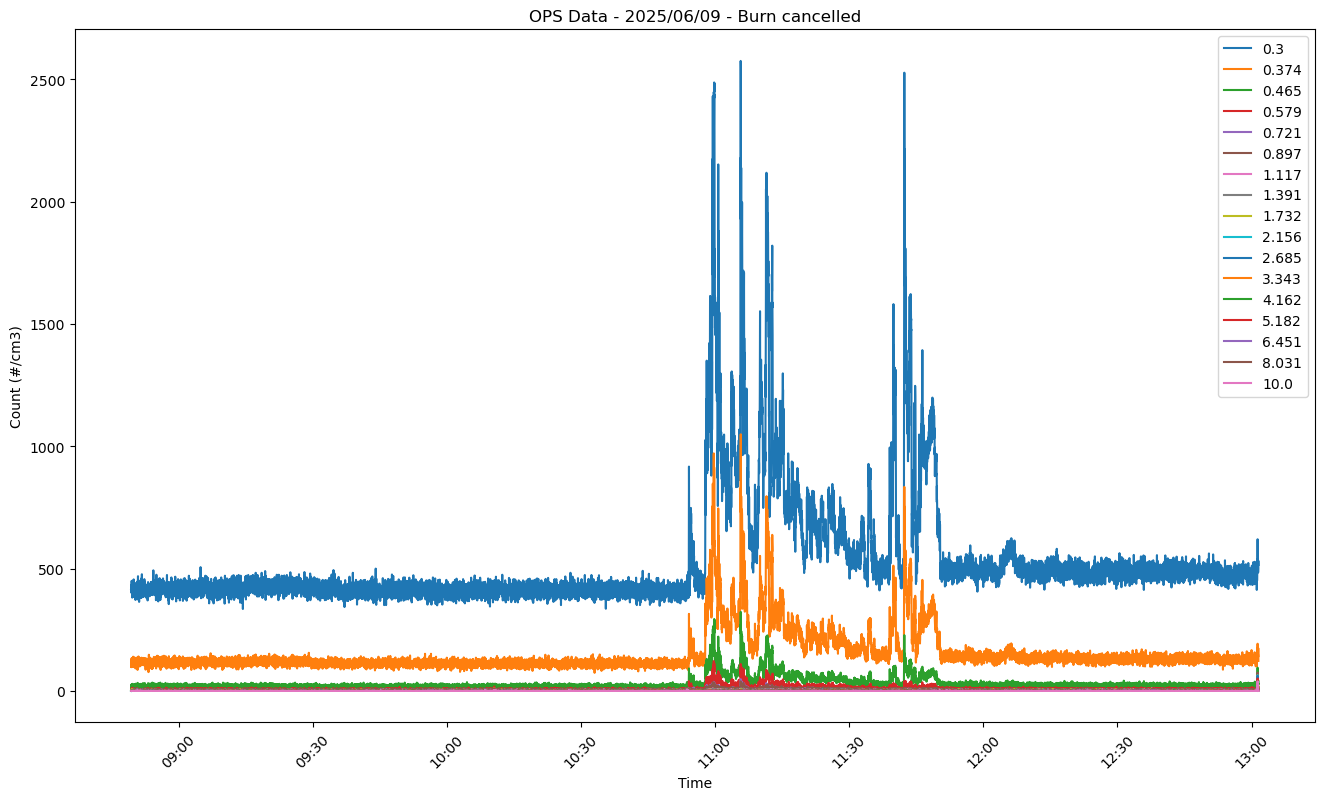

In [58]:

plt.figure(figsize=(16, 9))
for b in ops_2[0]['Bin Cut Points'].keys():
    plt.plot(ops_2[1]['datetime'], ops_2[1][f'Bin {b}'], label=f"{ops_2[0]['Bin Cut Points'][b]}")
        # Define the time format

time_formatter = mdates.DateFormatter("%H:%M")
# apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.xticks(rotation=45)
# plt.ylim(0, 30000)


plt.legend()
plt.title(f'OPS Data - {ops_2[0]["Test Start Date"]} - Burn cancelled')
plt.xlabel('Time')
plt.ylabel('Count (#/cm3)')
plt.show()

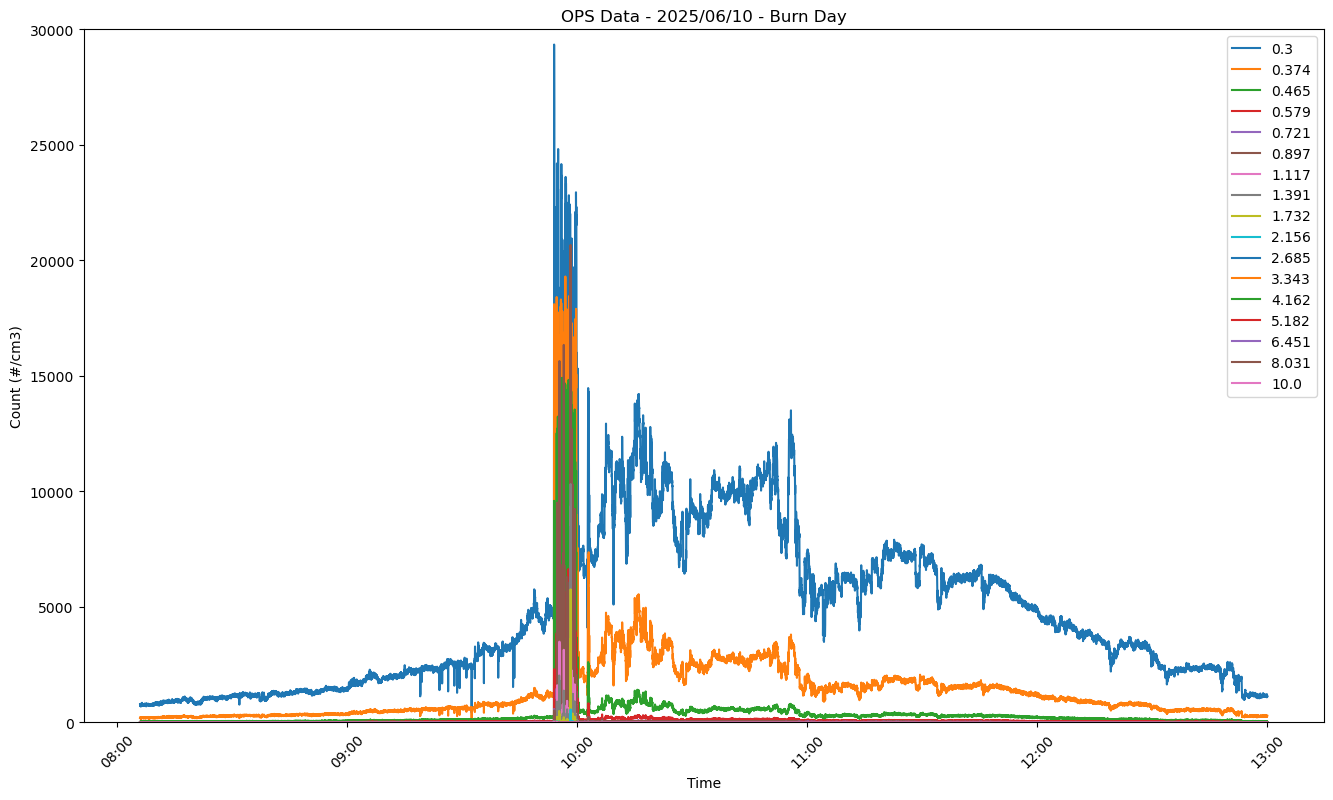

In [59]:
plt.figure(figsize=(16,9))
for b in ops_3[0]['Bin Cut Points'].keys():
    plt.plot(ops_3[1]['datetime'], ops_3[1][f'Bin {b}'], label=f"{ops_3[0]['Bin Cut Points'][b]}")

time_formatter = mdates.DateFormatter("%H:%M")
# apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.xticks(rotation=45)
plt.ylim(0, 30000)

plt.legend()
plt.title(f'OPS Data - {ops_3[0]["Test Start Date"]} - Burn Day')
plt.xlabel('Time')
plt.ylabel('Count (#/cm3)')
plt.show()

C:\Users\bmaro\AppData\Local\Temp\ipykernel_14844\4267967844.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


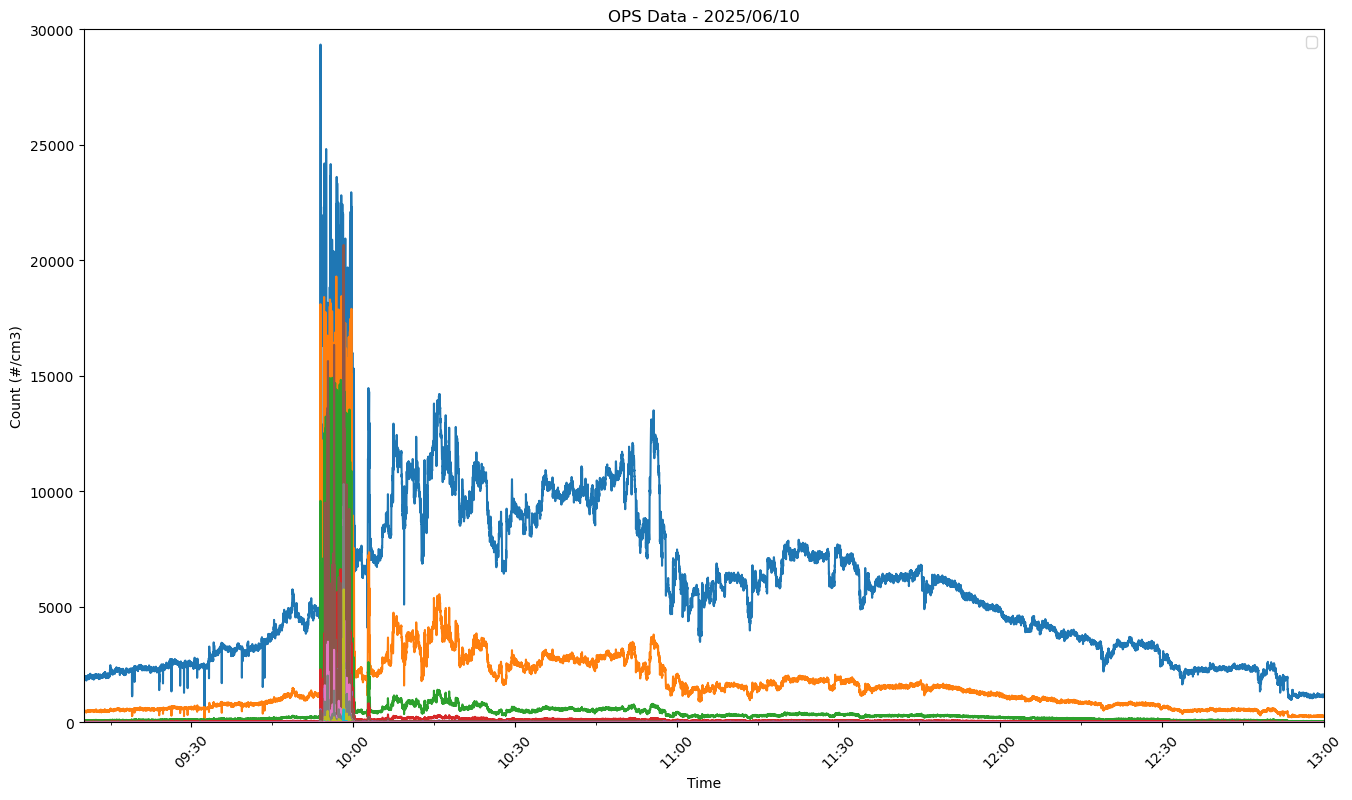

In [80]:
# Focus in around the 9:30 to 10:30 am period on June 10, 2025
plt.figure(figsize=(16,9))
for b in ops_3[0]['Bin Cut Points'].keys():
    plt.plot(ops_3[1]['datetime'], ops_3[1][f'Bin {b}'])

time_formatter = mdates.DateFormatter("%H:%M")
# apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))
plt.xticks(rotation=45)
plt.ylim(0, 30000)
plt.xlim(pd.Timestamp('2025-06-10 09:10:00'), pd.Timestamp('2025-06-10 13:00:00'))

# plt.axvline(x=pd.Timestamp('2025-06-10 09:15:00'), color='red', linestyle='--', label='09:15 - 1st Burn Location')
# plt.axvline(x=pd.Timestamp('2025-06-10 09:28:00'), color='red', linestyle='--', label='09:28 - 2nd Burn Location')
# plt.axvline(x=pd.Timestamp('2025-06-10 09:55:00'), color='red', linestyle='--', label='09:55 - Full Smoke')
# plt.axvline(x=pd.Timestamp('2025-06-10 10:00:00'), color='red', linestyle='--', label='10:00 - Noticable drop in smoke')
# plt.axvline(x=pd.Timestamp('2025-06-10 10:05:00'), color='red', linestyle='--', label='10:05 - Plumes are vertical')
# plt.axvline(x=pd.Timestamp('2025-06-10 10:15:00'), color='red', linestyle='--', label='10:15 - Burning completed.')

plt.legend()
plt.title(f'OPS Data - {ops_3[0]["Test Start Date"]}')
plt.xlabel('Time')
plt.ylabel('Count (#/cm3)')
plt.show()

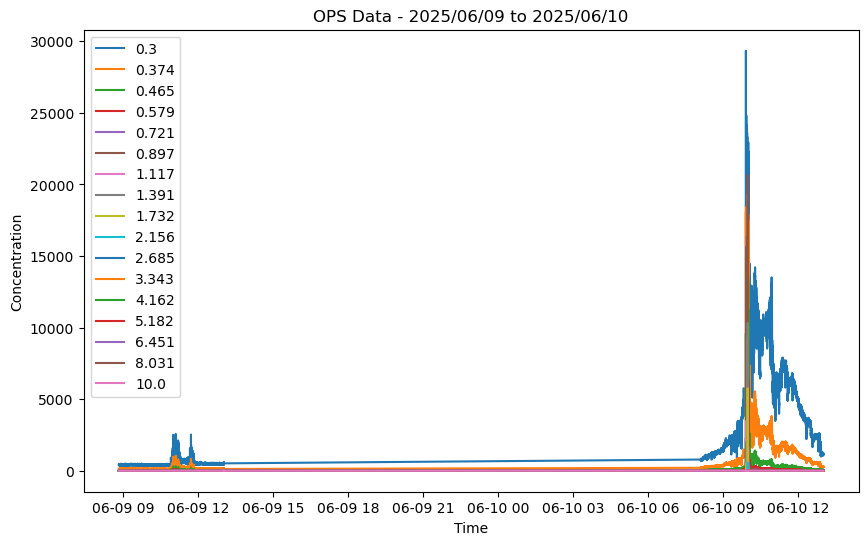

In [61]:
ops_data = pd.concat([ops_2[1], ops_3[1]], ignore_index=True)
plt.figure(figsize=(10, 6))
for b in ops_1[0]['Bin Cut Points'].keys():
    plt.plot(ops_data['datetime'], ops_data[f'Bin {b}'], label=f"{ops_1[0]['Bin Cut Points'][b]}")  
# Break x-axis so we can drop the night time data


plt.legend()
plt.title(f'OPS Data - {ops_2[0]["Test Start Date"]} to {ops_3[0]["Test Start Date"]}')
plt.xlabel('Time')
plt.ylabel('Concentration')
plt.show()


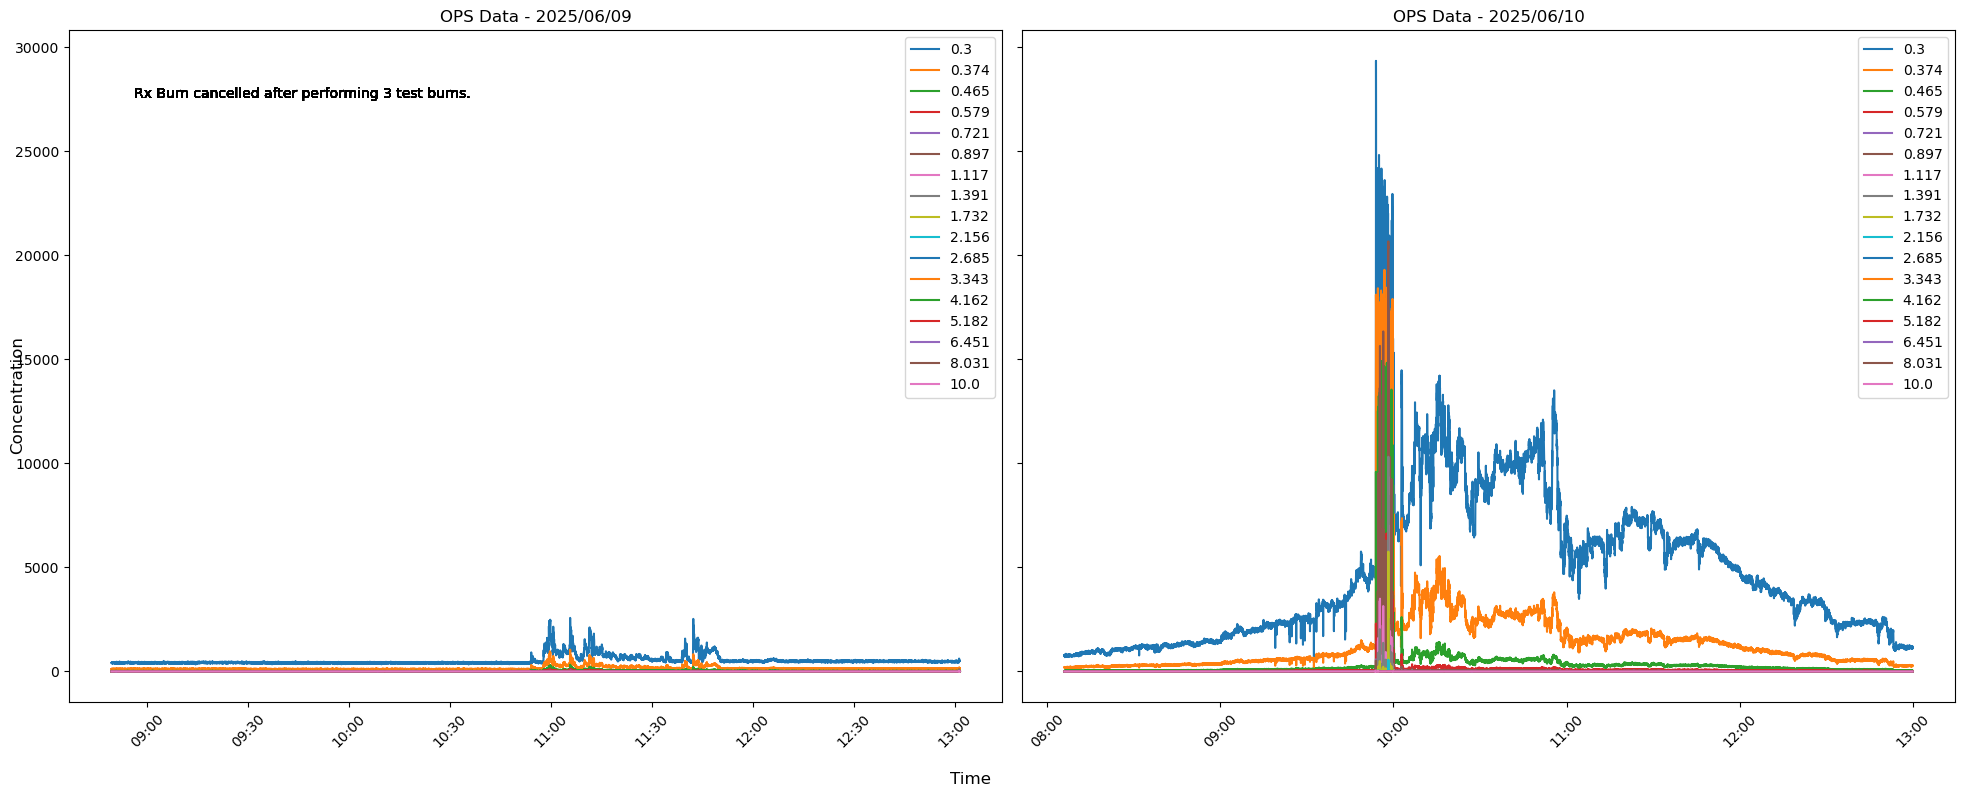

In [62]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

for b in ops_2[0]['Bin Cut Points'].keys():
    ax1.plot(ops_2[1]['datetime'], ops_2[1][f'Bin {b}'], label=f"{ops_2[0]['Bin Cut Points'][b]}")
    ax1.set_title(f'OPS Data - {ops_2[0]["Test Start Date"]}')
    ax1.text(0.25,.9, 'Rx Burn cancelled after performing 3 test burns.', transform=ax1.transAxes, ha='center')

for b in ops_3[0]['Bin Cut Points'].keys():
    ax2.plot(ops_3[1]['datetime'], ops_3[1][f'Bin {b}'], label=f"{ops_3[0]['Bin Cut Points'][b]}")
    ax2.set_title(f'OPS Data - {ops_3[0]["Test Start Date"]}')
    ax2.set_title(f'OPS Data - {ops_3[0]["Test Start Date"]}')
    # ax2.text(0.25,.9, 'Rx Burn performed. Starting at 9:15ish, moving locations and starting at burn location NNW at 9:35', transform=ax1.transAxes, ha='center')

for ax in (ax1, ax2):
    time_formatter = mdates.DateFormatter("%H:%M")
    ax.xaxis.set_major_formatter(time_formatter)
    ax.tick_params(axis='x', rotation=45)
    ax.legend() 

# Add a common x-axis label to the entire figure
fig.supxlabel('Time')

# Add a common y-axis label to the entire figure
fig.supylabel('Concentration')
plt.tight_layout()
plt.show()

# Reading DustTrak II Data
Now we will focus on the DustTrak II data. Each file represents one test and the first 19 rows, contain meta data. 


In [63]:
def read_dusttrak(csv_file_path):
    """ Reads the DustTrak data from a CSV file and returns a DataFrame with metadata.
    Returns (Tuple):
        metadata_dict (dict): Dictionary containing metadata from the DustTrak file.
        df (pd.DataFrame): DataFrame containing the DustTrak data.
    """
    # read the csv file
    with open(csv_file_path, 'r') as f:
        content = f.readlines()

    metadata = content[0:19]  # first 6 lines are metadata
    # convert metadata to a dictionary
    metadata_dict = {}
    for line in metadata:
        try:
            key, value = line.split(',')
            print(key, value)
            metadata_dict[key.strip()] = value.strip()
        except ValueError:
            pass

    df = pd.read_csv(csv_file_path, skiprows=19) 
    # convert columns to appropriate data types
    start_datetime = dt.datetime.strptime(
            f"{metadata_dict['Test Start Date']} {metadata_dict['Test Start Time']}"
            , "%m/%d/%Y %I:%M:%S %p"
        )
    print(f"Start datetime: {start_datetime}")
    df['datetime'] = start_datetime + pd.to_timedelta(df['Elapsed Time [s]'], unit='s')
    
    # reoder columns to have datetime first
    cols = df.columns.tolist()
    cols = cols[-1:] + cols[:-1]
    df = df[cols]

    return [metadata_dict, df]


In [ ]:
# TEST: Read DustTrak data
dts_file = os.path.join(proj_dir, r'..\data\DT\BURN TRIAL_001.csv')
data_dts = read_dusttrak(dts_file)
# Display the first few rows of the DustTrak data

data_dts[1].head()

Instrument Name DustTrak II

Model Number 8530

Serial Number 8530183103

Firmware Version 3.7

Calibration Date 08/02/2018

Test Name BURN TRIAL_001

Test Start Time 02:01:31 PM

Test Start Date 06/08/2025

Test Length [D:H:M] 0:5:9

Test Interval [M:S] 0:1

Mass Average [mg/m3] 0.056

Mass Minimum [mg/m3] 0.048

Mass Maximum [mg/m3] 1.20

Mass TWA [mg/m3] 0.036

Photometric User Cal 1.00

Flow User Cal 0.00

Errors 

Number of Samples 18592

Start datetime: 2025-06-08 14:01:31


,datetime,Elapsed Time [s],Mass [mg/m3],Alarms,Errors
0,2025-06-08 14:01:32,1,0.049,NaN,NaN
1,2025-06-08 14:01:33,2,0.049,NaN,NaN
2,2025-06-08 14:01:34,3,0.050,NaN,NaN
3,2025-06-08 14:01:35,4,0.049,NaN,NaN
4,2025-06-08 14:01:36,5,0.048,NaN,NaN


In [ ]:
dts_1_file = os.path.join(proj_dir, r'..\data\DT\BURN TRIAL_001.csv')     # Won't use this file. Too few data points.
dts_2_file = os.path.join(proj_dir, r'..\data\DT\BURN TRIAL_002.csv')
dts_3_file = os.path.join(proj_dir, r'..\data\DT\BURN TRIAL_003.csv')

dts_1 = read_dusttrak(dts_1_file)
dts_2 = read_dusttrak(dts_2_file)
dts_3 = read_dusttrak(dts_3_file)

# trim first 10 minutes of day 2 and day 3 data
dts_2[1] = dts_2[1][dts_2[1]['datetime'] >= dts_2[1]['datetime'].min() + pd.Timedelta(minutes=10)]
dts_3[1] = dts_3[1][dts_3[1]['datetime'] >= dts_3[1]['datetime'].min() + pd.Timedelta(minutes=10)]

Instrument Name DustTrak II

Model Number 8530

Serial Number 8530183103

Firmware Version 3.7

Calibration Date 08/02/2018

Test Name BURN TRIAL_001

Test Start Time 02:01:31 PM

Test Start Date 06/08/2025

Test Length [D:H:M] 0:5:9

Test Interval [M:S] 0:1

Mass Average [mg/m3] 0.056

Mass Minimum [mg/m3] 0.048

Mass Maximum [mg/m3] 1.20

Mass TWA [mg/m3] 0.036

Photometric User Cal 1.00

Flow User Cal 0.00

Errors 

Number of Samples 18592

Start datetime: 2025-06-08 14:01:31
Instrument Name DustTrak II

Model Number 8530

Serial Number 8530183103

Firmware Version 3.7

Calibration Date 08/02/2018

Test Name BURN TRIAL_002

Test Start Time 08:04:53 AM

Test Start Date 06/09/2025

Test Length [D:H:M] 0:5:3

Test Interval [M:S] 0:1

Mass Average [mg/m3] 0.061

Mass Minimum [mg/m3] 0.052

Mass Maximum [mg/m3] 0.374

Mass TWA [mg/m3] 0.039

Photometric User Cal 1.00

Flow User Cal 0.00

Errors 

Number of Samples 18210

Start datetime: 2025-06-09 08:04:53
Instrument Name DustTrak II

Mo

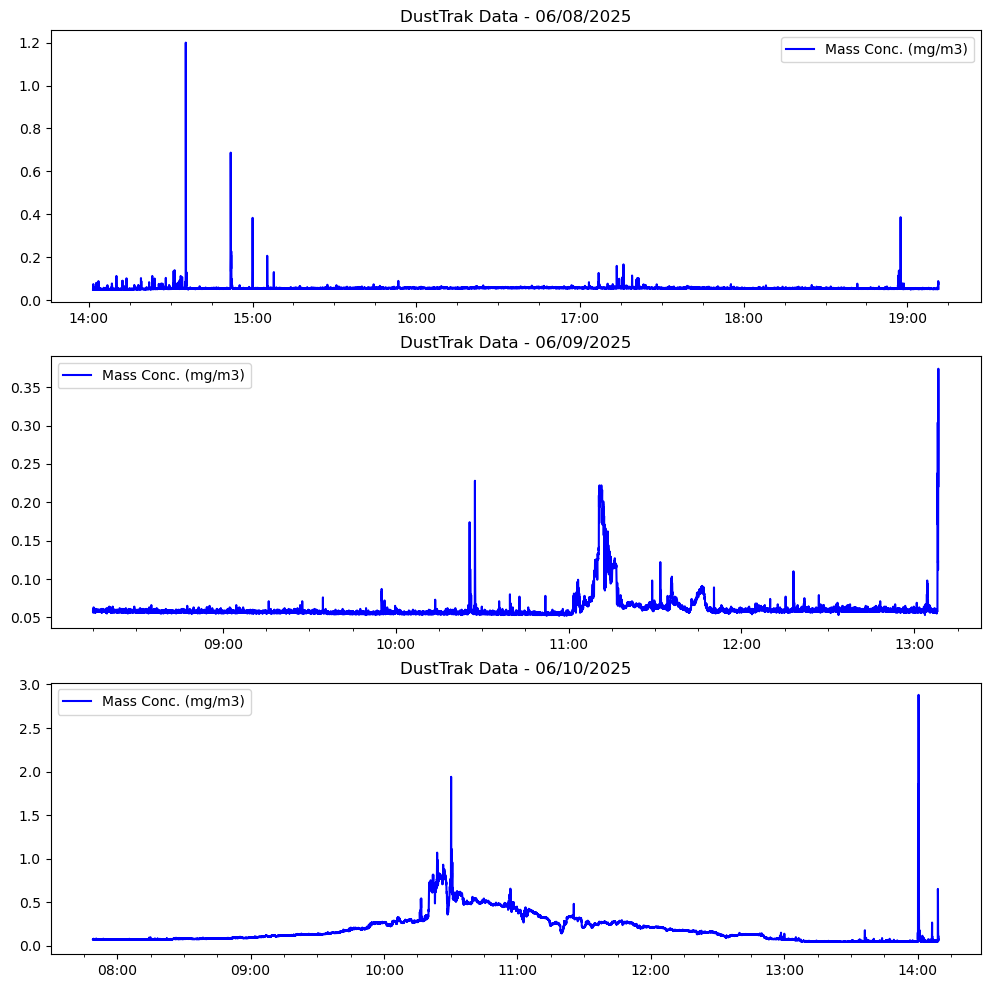

In [66]:
# Create 3 plots, 1 column, 3 rows and plot the Mass Concentration (mg/m3) for each day
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12))
time_formatter = mdates.DateFormatter("%H:%M")

ax1.plot(dts_1[1]['datetime'], dts_1[1]['Mass [mg/m3]'], label='Mass Conc. (mg/m3)', color='blue')
ax1.set_title(f'DustTrak Data - {dts_1[0]["Test Start Date"]}')
ax1.legend()
ax1.xaxis.set_major_formatter(time_formatter)
ax1.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))

ax2.plot(dts_2[1]['datetime'], dts_2[1]['Mass [mg/m3]'], label='Mass Conc. (mg/m3)', color='blue')
ax2.set_title(f'DustTrak Data - {dts_2[0]["Test Start Date"]}')
ax2.legend()
ax2.xaxis.set_major_formatter(time_formatter)
ax2.xaxis.set_major_formatter(time_formatter)
ax2.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))

ax3.plot(dts_3[1]['datetime'], dts_3[1]['Mass [mg/m3]'], label='Mass Conc. (mg/m3)', color='blue')
ax3.set_title(f'DustTrak Data - {dts_3[0]["Test Start Date"]}')
ax3.legend()
ax3.xaxis.set_major_formatter(time_formatter)
ax3.xaxis.set_major_formatter(time_formatter)
ax3.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))



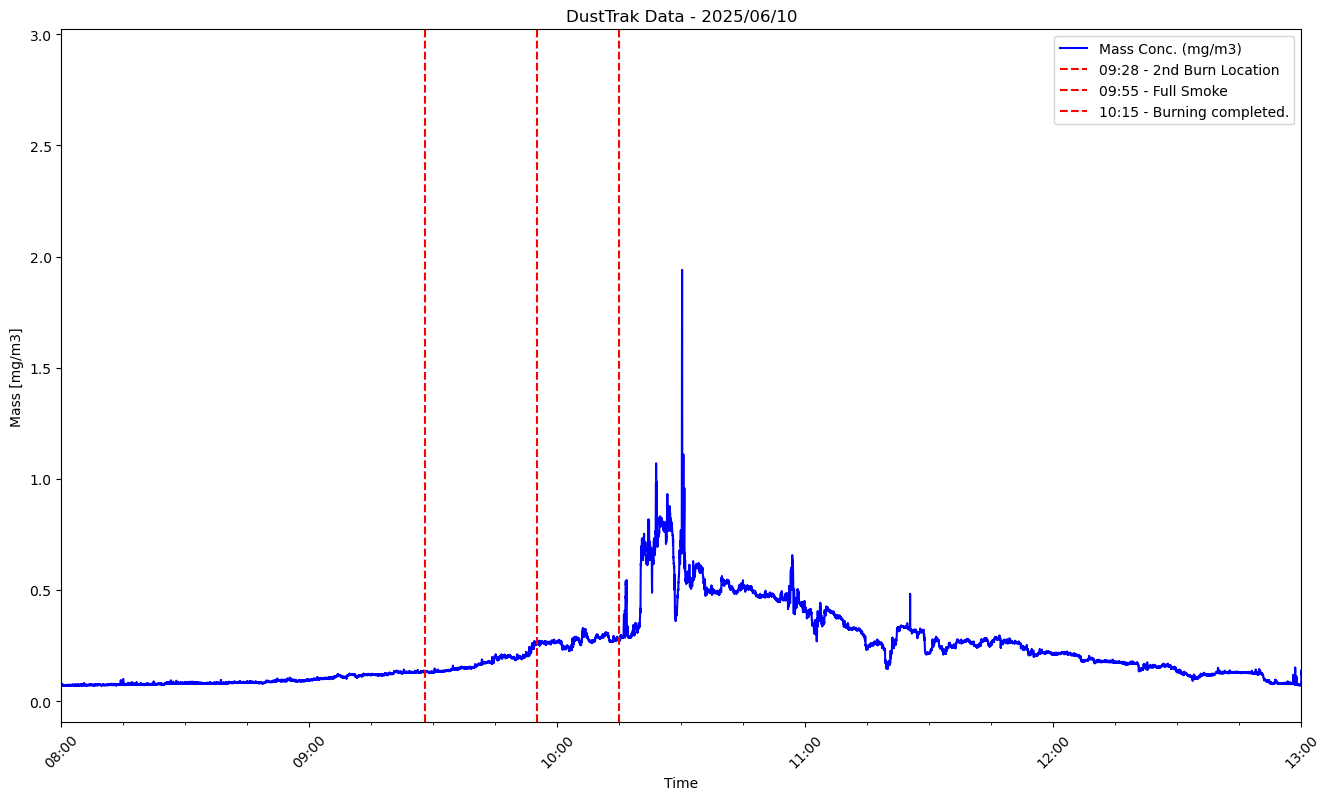

In [81]:
# Focus in around the 9:30 to 10:30 am period on June 10, 2025
plt.figure(figsize=(16,9))
plt.plot(dts_3[1]['datetime'], dts_3[1]['Mass [mg/m3]'], label='Mass Conc. (mg/m3)', color='blue')
plt.title(f'DustTrak Data - {dts_3[0]["Test Start Date"]}')
plt.legend()
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))

time_formatter = mdates.DateFormatter("%H:%M")
# apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(time_formatter)
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0,15,30,45]))
plt.xticks(rotation=45)
plt.xlim(pd.Timestamp('2025-06-10 09:00:00'), pd.Timestamp('2025-06-10 10:30:00'))

# plt.axvline(x=pd.Timestamp('2025-06-10 09:15:00'), color='red', linestyle='--', label='09:15 - 1st Burn Location')
plt.axvline(x=pd.Timestamp('2025-06-10 09:28:00'), color='red', linestyle='--', label='09:28 - 2nd Burn Location')
plt.axvline(x=pd.Timestamp('2025-06-10 09:55:00'), color='red', linestyle='--', label='09:55 - Full Smoke')
# plt.axvline(x=pd.Timestamp('2025-06-10 10:00:00'), color='red', linestyle='--', label='10:00 - Noticable drop in smoke')
# plt.axvline(x=pd.Timestamp('2025-06-10 10:05:00'), color='red', linestyle='--', label='10:05 - Plumes are vertical')
plt.axvline(x=pd.Timestamp('2025-06-10 10:15:00'), color='red', linestyle='--', label='10:15 - Burning completed.')

plt.xlim(pd.Timestamp('2025-06-10 08:00:00'), pd.Timestamp('2025-06-10 13:00:00'))
plt.legend()
plt.title(f'DustTrak Data - {ops_3[0]["Test Start Date"]}')
plt.xlabel('Time')
plt.ylabel('Mass [mg/m3]')
plt.show()

# Wind Data from UC-Davis Group
Contact Holly Oldroyd or Diane Wang

In [ ]:
temp_data_dir = os.path.join(proj_dir, r'..\data\02_processed\winds')
print(os.listdir(temp_data_dir))

['.DS_Store', 'Site1_wind_15min.mat', 'Site1_wind_1min.mat', 'Site2_wind_15min.mat', 'Site2_wind_1min.mat', 'WindDirection_15min.png', 'WindSpeed_15min.png']


In [ ]:
# Using scipy read .mat files for wind
site1_wind_1min = os.path.join(temp_data_dir, 'Site1_wind_1min.mat')

wind_data = scipy.io.loadmat(site1_wind_1min)
wind_data['Site1_1min']

array([[(array([[739776.83402778],
               [739776.83472222],
               [739776.83541667],
               ...,
               [739778.83194444],
               [739778.83263889],
               [739778.83333333]], shape=(2880, 1)), array([[nan],
               [nan],
               [nan],
               ...,
               [nan],
               [nan],
               [nan]], shape=(2880, 1)), array([[nan],
               [nan],
               [nan],
               ...,
               [nan],
               [nan],
               [nan]], shape=(2880, 1)), array([[nan],
               [nan],
               [nan],
               ...,
               [nan],
               [nan],
               [nan]], shape=(2880, 1)), array([[array(['timeStamp'], dtype='<U9'),
                array(['1.89m direction'], dtype='<U15'),
                array(['1.89m speed'], dtype='<U11'),
                array(['1.89m flag 225<dir<265'], dtype='<U22')]], dtype=object))  ]],
      dtype=[('time', 'O'

In [ ]:
wind_data['Site1_1min'][0][0][0]

array([[739776.83402778],
       [739776.83472222],
       [739776.83541667],
       ...,
       [739778.83194444],
       [739778.83263889],
       [739778.83333333]], shape=(2880, 1))

In [ ]:
def load_wind_data(mat_file_path: str, site_name: str, avg: str = "1min", round_time: bool = True) -> pd.DataFrame:
    """
    Load wind data from a .mat file into a pandas DataFrame.

    Parameters
    ----------
    mat_file_path : str
        Path to the .mat file.
    site_name : str
        Name of the site (e.g., "Site1", "Site2", "Site3").
    avg : str
        Averaging interval (e.g., "1min", "10min", "30min").
    round_time : bool
        If True, round time up to the nearest full minute.

    Returns
    -------
    pd.DataFrame
        DataFrame with time, direction, speed, and flag_angle.
    """
    mat_data = scipy.io.loadmat(mat_file_path)
    key = f"{site_name}_{avg}"

    if key not in mat_data:
        raise ValueError(f"Key {key} not found in {mat_file_path}. Available keys: {mat_data.keys()}")

    site_data = mat_data[key][0, 0]

    time = site_data['time'].flatten()
    direction = site_data['direction'].flatten()
    speed = site_data['speed'].flatten()
    flag_angle = site_data['flag_angle'].flatten()

    # Convert MATLAB datenum to Python datetime
    datetimes = [dt.datetime.fromordinal(int(t)) +
                 dt.timedelta(days=t % 1) -
                 dt.timedelta(days=366)
                 for t in time]

    dt_series = pd.to_datetime(datetimes)

    if round_time:
        dt_series = dt_series.ceil("min")  # round UP to nearest minute

    df = pd.DataFrame({
        'time': dt_series,
        'direction': direction,
        'speed': speed,
        'flag_angle': flag_angle
    })

    return df


# Test again with rounding enabled

# Test with the provided Site1 file and 1min average
df_site1_1min = load_wind_data(site1_wind_1min, "Site1", "1min")
df_site1_1min.head(50)

,time,direction,speed,flag_angle
0,2025-06-08 20:01:00,NaN,NaN,NaN
1,2025-06-08 20:02:00,NaN,NaN,NaN
2,2025-06-08 20:03:00,NaN,NaN,NaN
3,2025-06-08 20:04:00,NaN,NaN,NaN
4,2025-06-08 20:05:00,NaN,NaN,NaN
5,2025-06-08 20:06:00,NaN,NaN,NaN
6,2025-06-08 20:07:00,NaN,NaN,NaN
7,2025-06-08 20:08:00,NaN,NaN,NaN
8,2025-06-08 20:09:00,NaN,NaN,NaN
9,2025-06-08 20:10:00,NaN,NaN,NaN


# Metadata for my Instruments
N 40 37.175'
W 123 26.832'
Elevation 1312

In [ ]:
OPS_location = (40 + 37.175/60, -(123 + 26.832/60))  # (lat, lon)
DTS_location = (40 + 37.147/60, -(123 + 26.743/60))  # (lat, lon)

# convert to shapely Points so we can use geopandas and then create a shapefile
OPS_point = Point(OPS_location[1], OPS_location[0])  # Note: Point(lon, lat)
DTS_point = Point(DTS_location[1], DTS_location[0])  # Note: Point(lon, lat)
gdf = gpd.GeoDataFrame({'site': ['OPS', 'DTS'], 'geometry': [OPS_point, DTS_point]}, crs="EPSG:4326")
gdf.to_file(os.path.join(proj_dir, 'data', 'site_locations.shp'))
gdf


,site,geometry
0,OPS,POINT (-123.4472 40.61958)
1,DTS,POINT (-123.44572 40.61912)


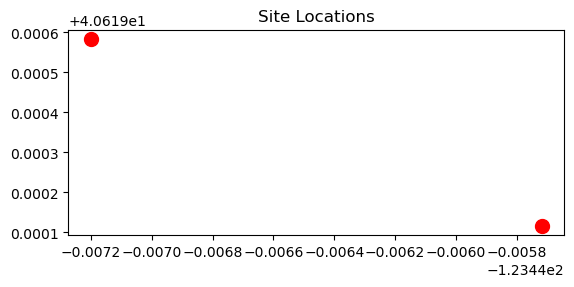

In [ ]:
# plot gdfs
gdf.plot(marker='o', color='red', markersize=100)
plt.title('Site Locations')
plt.show()